# MS12 — Prédiction ETA · Notebook 03 : Stratégie de production

**But.** Finaliser le modèle gagnant, l'interpréter (importance des features, SHAP), puis **geler** l'artefact
consommé tel quel par le service FastAPI (`main.py`). C'est le pont entre l'analyse et la production.

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
# Se placer à la racine du service (ms12-prediction) quel que soit le dossier d'exécution
while os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid", palette="deep")
os.makedirs("notebooks/figures", exist_ok=True)
from config import settings
print("Répertoire de travail :", os.getcwd())

Répertoire de travail : C:\Users\Anass\Desktop\SDIA\S9\PFE\transport-scolaire\ms12-prediction


**Étape 1 — Entraînement final + gel.** On lance le pipeline complet : benchmark, choix du gagnant, réentraînement sur toutes les données, sauvegarde des artefacts (`eta_model.pkl`, `eta_config.json`, `benchmark_summary.json`).

In [2]:
import train
train.main()
config = json.load(open(settings.config_path, encoding="utf-8"))
print("Algorithme gelé :", config["algorithme"], "| version", config["version"])
print("Métriques test (normaux) :", config["metrics_test"]["normaux"])
print("Gain vs baseline OSRM :", config["gain_vs_baseline_%"], "%")

[MS12] 4320 lignes | train=3600 test=720 | 26 features | incidents test=1.0%
  baseline_moyenne     MAE= 2.709 min R2=-0.005 (0.003s)


  linear               MAE= 1.367 min R2=0.154 (0.009s)
  ridge                MAE= 1.367 min R2=0.155 (0.005s)
  elasticnet           MAE= 1.322 min R2=0.164 (0.006s)
  knn                  MAE= 1.452 min R2=0.163 (0.003s)


  random_forest        MAE= 1.567 min R2=-0.011 (2.376s)


  extra_trees          MAE= 1.549 min R2=-0.131 (1.473s)


  gradient_boosting    MAE= 1.476 min R2=0.099 (1.031s)


  hist_gb              MAE= 1.705 min R2=0.085 (0.261s)


  xgboost              MAE= 1.675 min R2=-0.044 (0.544s)


  lightgbm             MAE= 1.926 min R2=0.026 (0.29s)

[MS12] 🏆 Gagnant : elasticnet — MAE=1.3219 min (baseline OSRM 2.7957 → gain 52.7%)
[MS12] Artefacts : data/eta_model.pkl | data/eta_config.json | data/benchmark_summary.json
Algorithme gelé : elasticnet | version ms12-prediction-v1
Métriques test (normaux) : {'MAE': 0.859, 'RMSE': 1.0791, 'R2': 0.8195, 'MAPE_%': 15.26}
Gain vs baseline OSRM : 52.7 %


**Étape 2 — Prédit vs réel.** On charge le modèle gelé et on trace la prédiction contre la réalité sur le test (les incidents ressortent en rouge = non prédictibles).

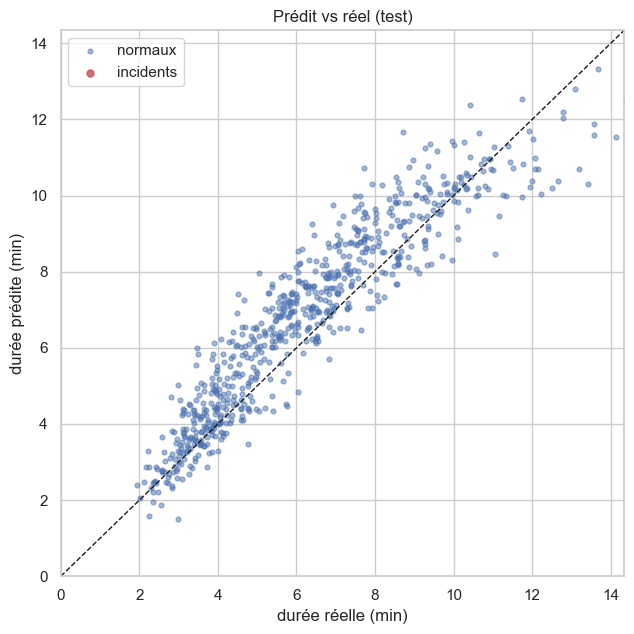

In [3]:
import joblib
from train import _charger_dataset, _split_temporel
from features import preparer_features, TARGET, LABEL

model = joblib.load(settings.model_path)
df = _charger_dataset(); _, test = _split_temporel(df)
Xte = preparer_features(test)[config["feature_columns"]]
pred = model.predict(Xte); yte = test[TARGET].to_numpy(); inc = test[LABEL].to_numpy() != "none"

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(yte[~inc], pred[~inc], s=12, alpha=.5, label="normaux", color="#4c72b0")
ax.scatter(yte[inc], pred[inc], s=25, alpha=.8, label="incidents", color="#c44e52")
lim = [0, np.percentile(yte, 99)]
ax.plot(lim, lim, "k--", lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("durée réelle (min)"); ax.set_ylabel("durée prédite (min)")
ax.set_title("Prédit vs réel (test)"); ax.legend()
plt.tight_layout(); plt.savefig(f"notebooks/figures/03_predit_vs_reel.png", dpi=110, bbox_inches="tight"); plt.show()

**Étape 3 — Résidus.** Les résidus des trajets normaux doivent être centrés et resserrés.

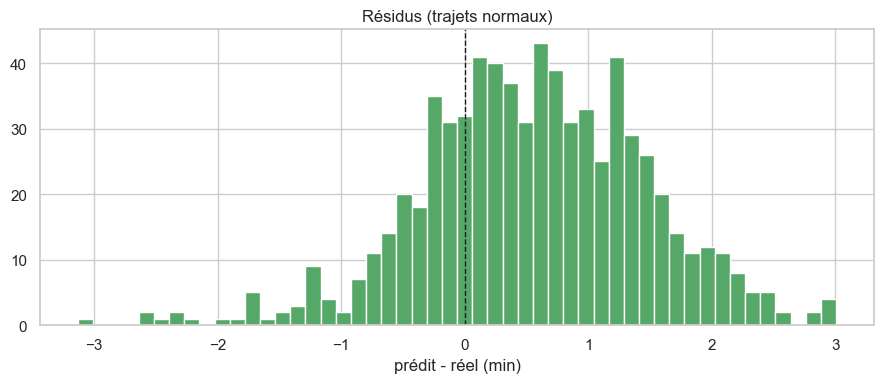

Résidu normaux : moyenne=0.550  écart-type=0.921 min


In [4]:
resid = pred - yte
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(resid[~inc], bins=50, color="#55a868")
ax.axvline(0, c="k", ls="--", lw=1); ax.set_title("Résidus (trajets normaux)"); ax.set_xlabel("prédit - réel (min)")
plt.tight_layout(); plt.savefig(f"notebooks/figures/03_residus.png", dpi=110, bbox_inches="tight"); plt.show()
print("Résidu normaux : moyenne=%.3f  écart-type=%.3f min" % (resid[~inc].mean(), resid[~inc].std()))

**Étape 4 — Importance des features.** Ce qui pilote la prédiction (issu de `eta_config.json`).

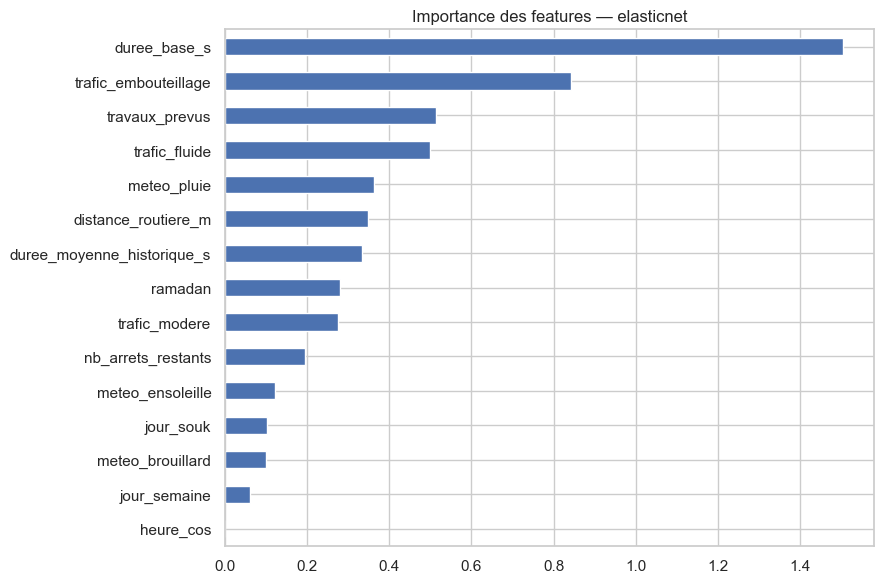

In [5]:
imp = config.get("importances", {})
if imp:
    s = pd.Series(imp).sort_values()
    fig, ax = plt.subplots(figsize=(9, 6))
    s.plot.barh(ax=ax, color="#4c72b0"); ax.set_title(f"Importance des features — {config['algorithme']}")
    plt.tight_layout(); plt.savefig(f"notebooks/figures/03_importances.png", dpi=110, bbox_inches="tight"); plt.show()
else:
    print("Pas d'importances exposées par ce modèle.")

**Étape 5 — SHAP (optionnel).** Explication fine des contributions (si `shap` est installé et le modèle compatible).

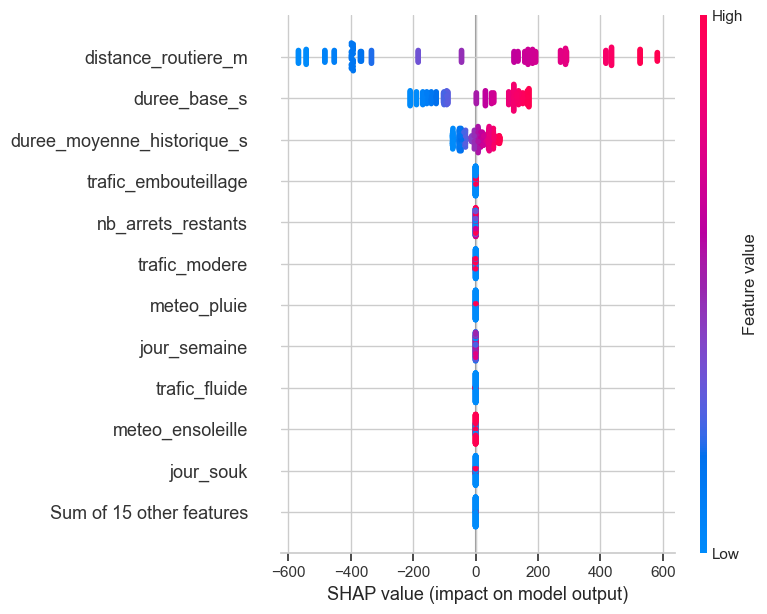

In [6]:
try:
    import shap
    est = model.steps[-1][1] if hasattr(model, "steps") else model
    Xs = Xte.sample(min(300, len(Xte)), random_state=42)
    explainer = shap.Explainer(est, Xs)
    sv = explainer(Xs)
    shap.plots.beeswarm(sv, max_display=12, show=False)
    plt.tight_layout(); plt.savefig(f"notebooks/figures/03_shap.png", dpi=110, bbox_inches="tight"); plt.show()
except Exception as e:
    print("SHAP ignoré :", e)

**Étape 6 — Config gelée (consommée par FastAPI).** Le service `main.py` charge ce même artefact — zéro divergence entre l'analyse et la production.

In [7]:
print(json.dumps({k: config[k] for k in
     ["version","algorithme","cible","n_lignes","n_features","mae_minutes","gain_vs_baseline_%","dateCalcul"]},
     indent=2, ensure_ascii=False))
print("\nArtefacts :", settings.model_path, "|", settings.config_path, "|", settings.benchmark_path)

{
  "version": "ms12-prediction-v1",
  "algorithme": "elasticnet",
  "cible": "duree_reelle_min",
  "n_lignes": 4320,
  "n_features": 26,
  "mae_minutes": 1.3219,
  "gain_vs_baseline_%": 52.7,
  "dateCalcul": "2026-07-01T22:37:21.791273+00:00"
}

Artefacts : data/eta_model.pkl | data/eta_config.json | data/benchmark_summary.json


### Conclusion du notebook 03
- Modèle gagnant **réentraîné sur toutes les données** et **gelé** (`eta_model.pkl` + `eta_config.json`).
- Interprétabilité fournie (importances / SHAP) pour le mémoire.
- Le service **MS12** (`POST /api/eta/predict`) sert exactement ce modèle → cohérence garantie.